# Case Study: Prioritising Vaccination for the Elderly in Covasim

This tutorial walks through the third case study (Section 5.3) of our paper
[*Testing Causality in Scientific Modelling Software*](https://dl.acm.org/doi/10.1145/3607184).
We use the Causal Testing Framework (CTF) to test how a change in vaccination policy affects the outputs of
[Covasim](https://github.com/InstituteforDiseaseModeling/covasim), a widely used COVID-19 simulator. Along the way, we
uncover a real bug that was later confirmed and fixed by the Covasim developers.

This is a relatively simple case study, and a good place to start if you're new to causal testing. The data comes
from a set of Covasim runs where the only thing that differs between the two groups is the vaccination policy. This
means we don't have to worry about confounding, and can focus on the basic steps of causal testing.

By the end of this tutorial you will have:

1. written down the expected effects of a vaccination policy as **metamorphic relations**;
2. used the causal DAG to check for confounding (**identification**);
3. run **causal test cases** to estimate the effect of the policy on four outputs;
4. used the test results to diagnose a **bug** in Covasim.

You only need basic familiarity with Python and pandas.

## The system under test: Covasim

Covasim is an *agent-based* model of COVID-19. It simulates a population of individual people ("agents") who live in
households, attend schools and workplaces, and mix in the community. The virus spreads between agents through these
contacts. Covasim is used to explore the impact of interventions such as testing, contact tracing, and vaccination. It
has informed policy decisions in the UK, US, and Australia, among other countries.

Covasim is a challenging system to test:

* it has dozens of inputs and outputs, with complex interactions between them;
* it is **non-deterministic**, so the same inputs give different outputs on each run;
* there's usually no way of knowing what the "correct" output for a given input should be.

This makes it a natural candidate for (statistical) metamorphic testing.

## What do we expect?

We compare two vaccination policies. In both, the (default) Pfizer vaccine becomes available from day 7 of the
simulation:

* **control:** anyone can be vaccinated;
* **treatment:** vaccination is *prioritised for the elderly*. Older agents are much more likely to be offered the
  vaccine than younger ones.

We're interested in the effect of switching from the control to the treatment policy on four outputs:

| Output | Column in data | Expected effect of prioritising the elderly | Why? |
|---|---|---|---|
| Cumulative infections | `cum_infections` | **increase** | Fewer younger people, who have the most contacts at school and work, are vaccinated. |
| Number of doses given | `cum_vaccinations` | **decrease** | The policy is more restrictive and there are fewer elderly agents. |
| Number of people vaccinated | `cum_vaccinated` | **decrease** | As above. |
| Maximum doses per person | `max_doses` | **no change** | The vaccine is given at most twice per person, whatever the policy. |

Each row of this table is a metamorphic relation that we'll turn into a causal test case.

## The causal testing workflow

Causal testing with the CTF follows these steps:

1. **Specify the causal DAG**, i.e. our assumptions about what causes what.
2. **Collect data**, i.e. runs of the system under test.
3. **Define causal test cases**, giving the treatment, the outcome, and the expected effect.
4. **Identification:** work out what (if anything) we need to adjust for to avoid confounding.
5. **Estimation:** fit a statistical model to estimate the causal effect.
6. **Apply the test oracle:** compare the estimated effect to the expected one.

## Step 1: The causal DAG

A **causal DAG** records our assumptions about the system. Each arrow $X \rightarrow Y$ means "$X$ directly affects
$Y$", and a *missing* arrow means "$X$ does not affect $Y$". The DAG for this case study is included with the CTF.

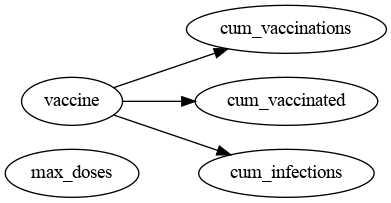

In [1]:
from causal_testing.examples.covasim import vaccinating_elderly as ve
from causal_testing.specification.causal_dag import CausalDAG

from tutorial_utils import render_dag


dag = CausalDAG(ve.dag_path)
render_dag(dag)

Here, `vaccine` is our treatment. It's `0` for the control policy and `1` for prioritising the elderly. The DAG says
that the vaccination policy affects infections, doses given, and people vaccinated. `max_doses` has no incoming arrow,
which says that it should *not* be affected by the policy.

Notice that nothing in the DAG points *into* `vaccine`. That will be important when we come to identification in
Step 4.

## Step 2: The data

The data for this case study is included with the CTF as a CSV file, so you don't need to install or run Covasim. It
contains 60 runs of Covasim (version 3.0.7): 30 with the control policy and 30 prioritising the elderly. Apart from the
vaccination policy, every run used the same settings. These were the default Covasim parameters, except for a
simulation length of 50 days, a population of 50,000 agents, and 1000 initially infected agents. Each run used a
different random seed.

Using pre-recorded data like this is common in causal testing. It means that tests can be re-run quickly and
reproducibly, even if the exact version of the software that produced the data is no longer available.

Let's load the data.

In [2]:
import pandas as pd

df = ve.df
df

,treatment_group,pop_size,pop_type,pop_infected,n_days,vaccine_type,use_waning,cum_infections,cum_deaths,cum_recoveries,cum_vaccinations,cum_vaccinated,rand_seed,target_elderly,vaccine,max_doses
0,control,50000,hybrid,1000,50,pfizer,True,4034,11,4000,149992,50000,5453,False,0,2
1,control,50000,hybrid,1000,50,pfizer,True,4006,21,3960,149990,50000,8002,False,0,2
2,control,50000,hybrid,1000,50,pfizer,True,3968,19,3923,149990,50000,1214,False,0,2
3,control,50000,hybrid,1000,50,pfizer,True,4410,24,4336,149986,50000,5021,False,0,2
4,control,50000,hybrid,1000,50,pfizer,True,4160,15,4102,149993,50000,9456,False,0,2
5,control,50000,hybrid,1000,50,pfizer,True,4261,18,4209,149991,50000,1130,False,0,2
6,control,50000,hybrid,1000,50,pfizer,True,4162,13,4120,149994,50000,2110,False,0,2
7,control,50000,hybrid,1000,50,pfizer,True,4169,17,4127,149992,50000,4978,False,0,2
8,control,50000,hybrid,1000,50,pfizer,True,4197,12,4160,149992,50000,2381,False,0,2
9,control,50000,hybrid,1000,50,pfizer,True,4408,9,4366,149993,50000,7062,False,0,2


Each row is one run of Covasim. The `vaccine` column records the policy, and the `cum_*` and `max_doses` columns hold
the outputs at the end of the simulation. A quick look at the averages under each policy gives us an early idea of what
to expect:

In [3]:
outcomes = ["cum_infections", "cum_vaccinations", "cum_vaccinated", "max_doses"]
df.groupby("vaccine")[outcomes].mean().rename(index={0: "control (everyone)", 1: "treatment (prioritise elderly)"})

,cum_infections,cum_vaccinations,cum_vaccinated,max_doses
vaccine,,,,
control (everyone),4236.633333,149991.700000,50000.000000,2.0
treatment (prioritise elderly),6757.100000,632108.866667,533334.933333,2.0


Some of these numbers already look suspicious. We'll come back to them once we've run the tests.

## Step 3: Defining the causal test cases

We measure each effect using the **average treatment effect** (ATE). This is the expected change in an output when we
switch the policy from control (`vaccine = 0`) to treatment (`vaccine = 1`):

$$ATE = \mathbb{E}[Y \mid \text{vaccine} = 1] - \mathbb{E}[Y \mid \text{vaccine} = 0]$$

Each test case needs an **expected causal effect** to act as its test oracle. The CTF provides:

* `Positive()`, which passes if the whole 95% confidence interval of the ATE is above zero;
* `Negative()`, which passes if the whole 95% confidence interval is below zero;
* `NoEffect()`, which passes if the 95% confidence interval contains zero, or if the estimate is within a given
  tolerance `atol` of zero.

For `max_doses`, every run gives exactly 2. The true effect is therefore exactly zero, but tiny floating-point
rounding errors in the regression can give an estimate like $10^{-16}$, with an equally tiny confidence interval that
doesn't quite contain zero. To avoid failing the test on rounding error, we allow a tolerance of `atol=1e-6`.

In [4]:
from causal_testing.testing.causal_effect import Negative, NoEffect, Positive

expected_effects = {
    "cum_infections": Positive(),
    "cum_vaccinations": Negative(),
    "cum_vaccinated": Negative(),
    "max_doses": NoEffect(atol=1e-6),
}

## Step 4: Identification

Normally, we'd now use the DAG to check whether the effect of the treatment on each outcome is **confounded**, that is,
whether some other variable affects both of them and could make the raw relationship misleading.

Our DAG has no arrows into `vaccine`, so there's nothing that could affect both the treatment and the outcomes. This
matches how the data was generated. The vaccination policy was chosen independently of everything else, and both
groups used exactly the same settings apart from the policy (and the random seed, which differs for every run).

The CTF confirms that there's nothing to adjust for:

In [5]:
{outcome: dag.identification("vaccine", outcome) for outcome in outcomes}

{'cum_infections': set(),
 'cum_vaccinations': set(),
 'cum_vaccinated': set(),
 'max_doses': set()}

## Step 5: Estimation

With nothing to adjust for, we can use the simplest possible regression model for each outcome $Y$:

$$Y \sim \beta_0 + \beta_1 \cdot \text{vaccine}$$

Because `vaccine` is either 0 or 1, the coefficient $\beta_1$ is exactly the difference between the average outcome in
the two groups. In other words, this is the conventional SMT approach of comparing the means of the source and
follow-up runs. The regression model also gives us confidence intervals for free.

## Step 6: Running the tests

In [6]:
from causal_testing.estimation.linear_regression_estimator import LinearRegressionEstimator
from causal_testing.testing.causal_test_case import CausalTestCase

results = []
for outcome, expected_effect in expected_effects.items():
    estimator = LinearRegressionEstimator(
        treatment_variable="vaccine",
        outcome_variable=outcome,
        control_value=0,
        treatment_value=1,
        adjustment_set=dag.identification("vaccine", outcome),
        alpha=0.05,  # i.e. compute 95% confidence intervals
    )
    test_case = CausalTestCase(
        expected_causal_effect=expected_effect,
        effect_measure="ate",
        estimator=estimator,
    )
    test_case.execute_test(df)

    estimate = test_case.result.effect_estimate
    results.append(
        {
            "outcome": outcome,
            "expected": str(expected_effect),
            "ate": estimate.effect_estimate.iloc[0],
            "ci_low": estimate.ci_low.iloc[0],
            "ci_high": estimate.ci_high.iloc[0],
            "test_outcome": test_case.result.outcome.name,
        }
    )

results = pd.DataFrame(results).set_index("outcome")
results

,expected,ate,ci_low,ci_high,test_outcome
outcome,,,,,
cum_infections,Positive,2.520467e+03,2.395520e+03,2.645413e+03,PASS
cum_vaccinations,Negative,4.821172e+05,4.813060e+05,4.829283e+05,FAIL
cum_vaccinated,Negative,4.833349e+05,4.825272e+05,4.841427e+05,FAIL
max_doses,NoEffect,7.216450e-16,5.370886e-16,9.062013e-16,PASS


We can confirm that the regression estimate is the same as simply comparing the group means:

In [7]:
means = df.groupby("vaccine")[outcomes].mean()
(means.loc[1] - means.loc[0]).rename("difference in means")

cum_infections        2520.466667
cum_vaccinations    482117.166667
cum_vaccinated      483334.933333
max_doses                0.000000
Name: difference in means, dtype: float64

## Interpreting the results

Two tests pass and two fail.

* **Infections pass.** Prioritising the elderly increases cumulative infections by roughly 2500 (out of a population of
  50,000), as expected.
* **Maximum doses pass.** The policy has no effect on the maximum number of doses per person.
* **Doses given and people vaccinated fail.** We expected these to *decrease*, but prioritising the elderly causes
  them to *increase* by nearly half a million!

Let's look at the raw data for the number of people vaccinated:

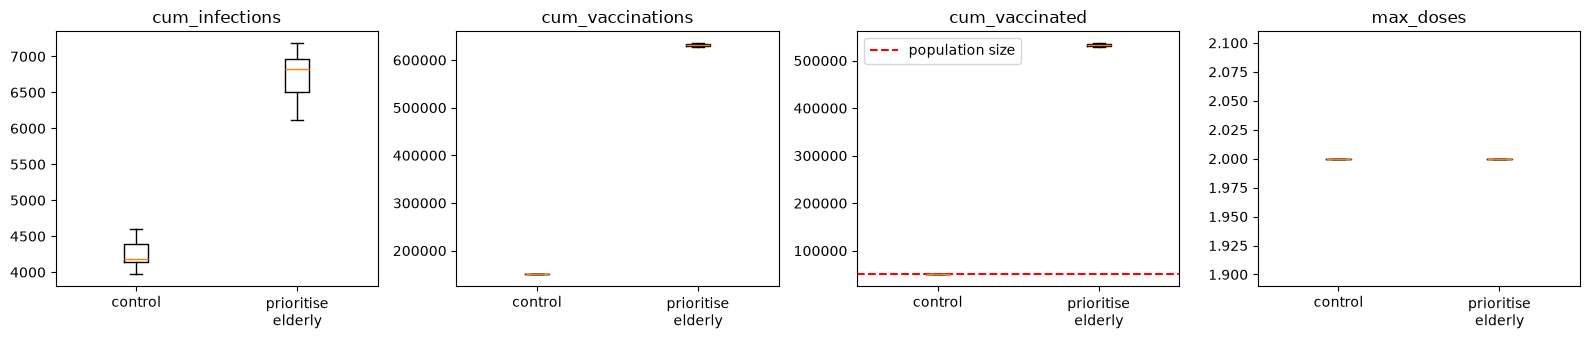

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, outcome in zip(axes, outcomes):
    ax.boxplot([df.loc[df["vaccine"] == v, outcome] for v in [0, 1]])
    ax.set_xticks([1, 2], ["control", "prioritise\nelderly"])
    ax.set_title(outcome)
axes[2].axhline(50_000, color="red", linestyle="--", label="population size")
axes[2].legend()
plt.tight_layout()
plt.show()

Under the control policy, `cum_vaccinated` is exactly 50,000, i.e. everyone is eventually vaccinated. But when we
prioritise the elderly, Covasim reports that on average over **530,000 people** have been vaccinated, in a population of
only 50,000. That's impossible. It's clearly a bug.

We reported this to the Covasim developers in
[September 2021](https://github.com/InstituteforDiseaseModeling/covasim/issues/370), and they confirmed that it was
fixed in version 3.1. The changelog for that version notes that *"Rescaling now does not reset vaccination status;
previously, dynamic rescaling erased it."*

This is a good example of why it pays to test properties that seem "obviously" true. The policy works as expected in
terms of infections, so a less thorough check might have missed the problem entirely.

## Summary

In this tutorial we used the CTF to carry out statistical metamorphic testing of Covasim:

1. We wrote down the expected effects of a vaccination policy as four **metamorphic relations**.
2. **Identification** showed that there was nothing to adjust for, because nothing in the DAG causes the treatment.
3. Each effect could then be estimated with a very simple regression model, which is equivalent to comparing group
   means as in conventional SMT.
4. Two of the four **causal tests** failed, revealing a genuine **bug** in Covasim that has since been fixed.

In terms of effort, we didn't need to write a complicated regression model or think hard about confounding. The
main effort went into writing down what we expected the policy to do.

This case study was simple because the two groups of runs differed only in their vaccination policy. In practice,
data is often messier than this, with many inputs varying at once. That's the subject of the
[next case study](covasim_disease_variants.ipynb), where we use the CTF to test Covasim with confounded data.

## Further resources

* [Testing Causality in Scientific Modelling Software (paper)](https://dl.acm.org/doi/10.1145/3607184)
* [Covasim on GitHub](https://github.com/InstituteforDiseaseModeling/covasim)
* [The Covasim bug report](https://github.com/InstituteforDiseaseModeling/covasim/issues/370)
* [Causal Testing Framework on GitHub](https://github.com/CITCOM-project/CausalTestingFramework)
* [Causal Testing Framework documentation](https://causal-testing-framework.readthedocs.io/en/latest/index.html)